# 03 · Safety logic: turning a species guess into a verdict

The classifier outputs a probability over 1,000 species. Someone holding
a plant needs one of three answers. This notebook is that conversion,
and nearly all of the project's safety-relevant design lives here.

The conversion is not a formality. A model 60% sure of a harmless
species and 30% sure of a lethal one has not given a safe answer, even
though its top guess is harmless. What to do with that distribution is a
design problem, handled by explicit rules rather than anything learned.

One asymmetry drives every rule. Calling a safe plant toxic costs
somebody a houseplant. Calling a toxic plant safe can cost somebody
their cat.

*Assumes the verified/inferred distinction from
[`01_the_data_problem`](01_the_data_problem.ipynb) and the model output
from [`02_training`](02_training.ipynb).*

## 1. Why a classifier output is not a verdict

Take a real distribution and try to read a safety answer off it.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

from plant_toxicity_checker import species_match
from plant_toxicity_checker.config import (
    CANDIDATE_FLOOR,
    DEFAULT_RUN,
    MIN_CONFIDENCE,
    TOXICITY_TABLE_PATH,
)
from plant_toxicity_checker.toxicity import load_table
from plant_toxicity_checker.verdict import Prediction, assess

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 92}}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

OUTPUTS_DIR = Path("../outputs")
TABLE = load_table(TOXICITY_TABLE_PATH)
TOXICITY_INDEX = species_match.build_toxicity_index(TABLE)

TIER_COLOR = {"toxic": "#b3202c", "caution": "#c77700",
              "likely_safe": "#2e7d32"}
TIER_LABEL = {"toxic": "TOXIC", "caution": "CAUTION",
              "likely_safe": "LIKELY SAFE"}


def tier_of(*pairs, **kwargs):
    """Run `assess` on (species, confidence) pairs and hand back the
    verdict. Anything not listed is treated as unseen mass."""
    return assess([Prediction(s, c) for s, c in pairs], TABLE, **kwargs)


print(f"thresholds: confidence floor {MIN_CONFIDENCE:.0%}, "
      f"candidate floor {CANDIDATE_FLOOR:.0%}")
print(f"toxicity table: {len(TABLE)} entries, "
      f"{sum(1 for e in TABLE if e.verified)} hand-verified")

thresholds: confidence floor 80%, candidate floor 5%
toxicity table: 571 entries, 85 hand-verified


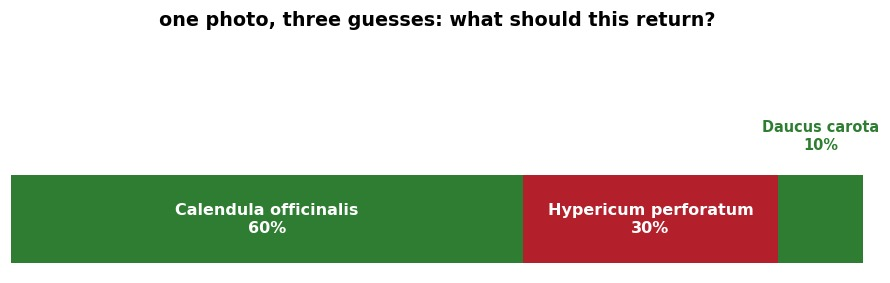

assess() returns: CAUTION
   - Confidence 60% is below 80%; treat as toxic.
   - Plausible alternative 'Hypericum perforatum' (30%) is toxic to cats.


In [2]:
# A distribution where the top guess is harmless and the runner-up is
# not. Hypericum perforatum is verified toxic; Calendula officinalis is
# verified non-toxic.
EXAMPLE = [("Calendula officinalis", 0.60),
           ("Hypericum perforatum", 0.30),
           ("Daucus carota", 0.10)]

figure, axis = plt.subplots(figsize=(10, 2.8))
left = 0.0
for name, share in EXAMPLE:
    match = species_match.lookup_toxicity(name, TOXICITY_INDEX)
    # toxicity_side gives "toxic" / "non_toxic" / None. Testing the
    # category string would be a trap: "exact - non-toxic" also ends
    # in "toxic".
    side = species_match.toxicity_side(match)
    color = TIER_COLOR["toxic" if side == "toxic" else "likely_safe"]
    axis.barh(0, share, left=left, color=color, height=0.5)
    if share >= 0.18:
        axis.text(left + share / 2, 0, f"{name}\n{share:.0%}",
                  ha="center", va="center", color="white", fontsize=10.5,
                  fontweight="bold")
    else:
        axis.text(left + share / 2, 0.38, f"{name}\n{share:.0%}",
                  ha="center", va="bottom", color=color, fontsize=9.5,
                  fontweight="bold")
    left += share
axis.set_xlim(0, 1)
axis.set_ylim(-0.3, 1.05)
axis.axis("off")
axis.set_title("one photo, three guesses: what should this return?",
               fontsize=12.5, fontweight="bold")
plt.show()

result = tier_of(*EXAMPLE)
print(f"assess() returns: {result.status.value.upper()}")
for reason in result.reasons:
    print(f"   - {reason}")

No threshold on the top prediction alone works here. Set it low and the
toxic runner-up gets ignored. Set it high and almost nothing is ever
answerable, including the easy cases.

The distribution has information the top-1 number throws away: *which*
species the remaining mass sits on. Everything below uses that.

## 2. The three tiers

| Tier | Claims | Does not claim |
|---|---|---|
| **TOXIC** | the best match, or its genus, is listed toxic by ASPCA | that the identification is right |
| **CAUTION** | this cannot be shown to be safe | that it is dangerous |
| **LIKELY SAFE** | every plausible candidate has a hand-verified non-toxic entry | that the plant is harmless to eat |

Two of these are read wrongly by default.

**CAUTION is an answer, not a failure.** It says the evidence does not
support "safe". Section 8 shows it is the commonest outcome by a wide
margin, which is a fact about the toxicity table rather than a bug.

**LIKELY SAFE is narrow.** ASPCA's "non-toxic" means *will not poison
your cat*, not *harmless*. A non-toxic plant can still cause a blockage
or an upset stomach, which is why the wording is "likely safe" and why
every verdict repeats that only one plant in the photo was assessed.

## 3. The decision procedure, step by step

`verdict.assess` takes the full distribution and the toxicity table. In
order:

1. **Sort, and look up the top match.** If its category is `exact -
   toxic` or `genus - toxic (direct)`, return **TOXIC** immediately.
   There is no confidence floor on this branch: a likely-toxic plant is
   flagged whether or not the model is sure.
2. **Build the candidate set**: every species at or above the **5%**
   candidate floor, plus the top match even if it falls below.
3. **Collect reasons.** Confidence under **80%** is a reason. A
   possibly-truncated list is a reason. Any candidate that is toxic, has
   a toxic relative, or lacks a verified non-toxic entry is a reason.
4. **Resolve.** Any reason at all gives **CAUTION**. Only an empty reason
   list gives **LIKELY SAFE**.

The tier is decided by whether the reason list is empty. That is the
whole mechanism, and it is why the default is never "safe".

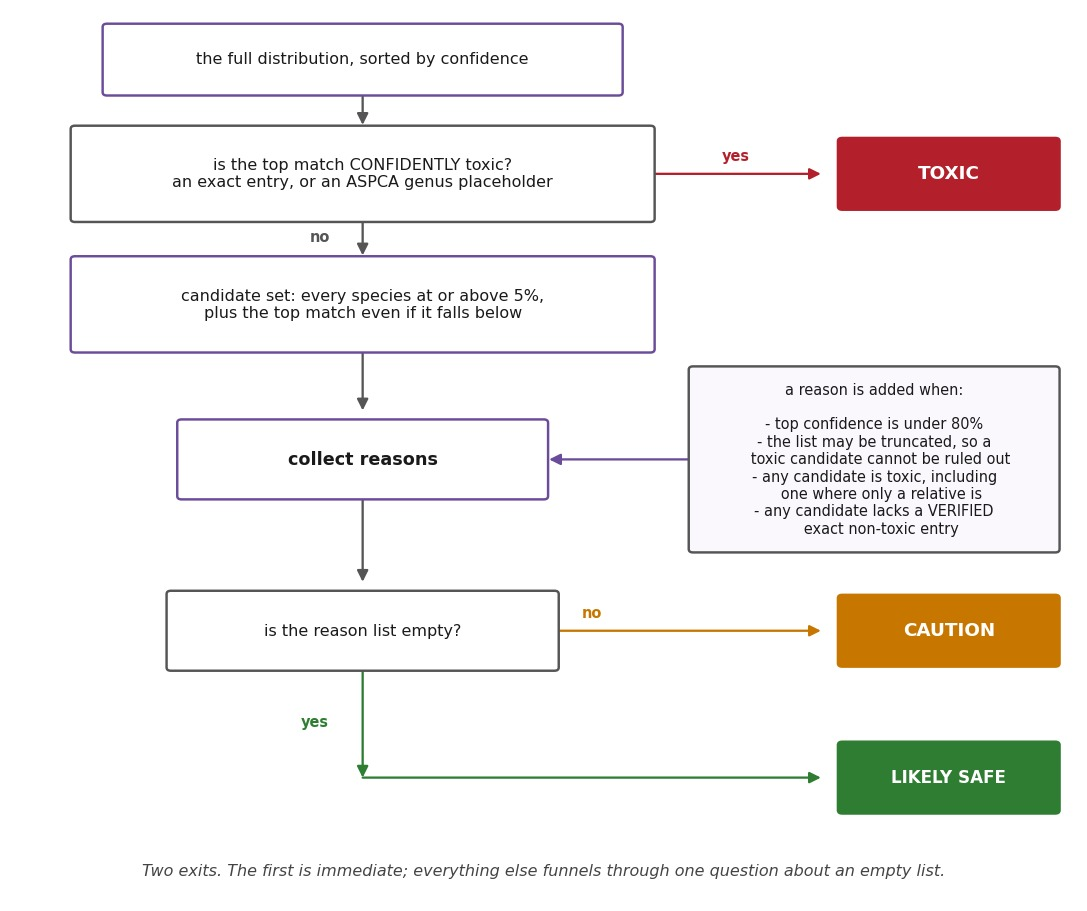

In [3]:
NL = chr(10)


def box(xy, w, h, text, edge, fill="#ffffff", fontsize=10.5,
        weight="normal", color=None):
    x, y = xy
    axis.add_patch(FancyBboxPatch(
        (x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.4",
        linewidth=1.6, edgecolor=edge, facecolor=fill, zorder=2))
    axis.text(x, y, text, ha="center", va="center", fontsize=fontsize,
              color=color or "#1a1a1a", weight=weight, zorder=3)


def arrow(start, end, color="#555555", label=None, dx=0, dy=1.8):
    axis.add_patch(FancyArrowPatch(
        start, end, arrowstyle="-|>", mutation_scale=15, linewidth=1.5,
        color=color, zorder=1, shrinkA=0, shrinkB=0))
    if label:
        axis.text((start[0] + end[0]) / 2 + dx, (start[1] + end[1]) / 2 + dy,
                  label, ha="center", va="center", fontsize=9.5,
                  color=color, weight="bold", zorder=3)


STEP, EXIT = "#6b4c9a", "#555555"
figure, axis = plt.subplots(figsize=(12.5, 10.5))
axis.set_xlim(0, 100)
axis.set_ylim(-9, 100)
axis.axis("off")

box((33, 94), 48, 8, "the full distribution, sorted by confidence", STEP)
arrow((33, 90), (33, 86))

box((33, 80), 54, 11,
    "is the top match CONFIDENTLY toxic?" + NL
    + "an exact entry, or an ASPCA genus placeholder", EXIT)
arrow((60, 80), (76, 80), color=TIER_COLOR["toxic"], label="yes", dy=2.2)
box((88, 80), 20, 8, "TOXIC", TIER_COLOR["toxic"],
    fill=TIER_COLOR["toxic"], fontsize=12, weight="bold", color="white")
arrow((33, 74.5), (33, 70), label="no", dx=-4, dy=0)

box((33, 64), 54, 11,
    "candidate set: every species at or above 5%," + NL
    + "plus the top match even if it falls below", STEP)
arrow((33, 58.5), (33, 51))

box((33, 45), 34, 9, "collect reasons", STEP, fontsize=11.5, weight="bold")
box((81, 45), 34, 22,
    "a reason is added when:" + NL + NL
    + "- top confidence is under 80%" + NL
    + "- the list may be truncated, so a" + NL
    + "   toxic candidate cannot be ruled out" + NL
    + "- any candidate is toxic, including" + NL
    + "   one where only a relative is" + NL
    + "- any candidate lacks a VERIFIED" + NL
    + "   exact non-toxic entry",
    EXIT, fill="#faf7fd", fontsize=9.5)
arrow((63.5, 45), (50.5, 45), color=STEP)
arrow((33, 40.5), (33, 30))

box((33, 24), 36, 9, "is the reason list empty?", EXIT)
arrow((51, 24), (76, 24), color=TIER_COLOR["caution"], label="no",
      dx=-9, dy=2.2)
box((88, 24), 20, 8, "CAUTION", TIER_COLOR["caution"],
    fill=TIER_COLOR["caution"], fontsize=12, weight="bold", color="white")
arrow((33, 19.5), (33, 6), label="yes", dx=-4.5, dy=0,
      color=TIER_COLOR["likely_safe"])
arrow((33, 6), (76, 6), color=TIER_COLOR["likely_safe"])
box((88, 6), 20, 8, "LIKELY SAFE", TIER_COLOR["likely_safe"],
    fill=TIER_COLOR["likely_safe"], fontsize=11, weight="bold",
    color="white")

axis.text(50, -6,
          "Two exits. The first is immediate; everything else funnels "
          "through one question about an empty list.",
          ha="center", fontsize=10.5, color="#444444", style="italic")
plt.show()

Two asymmetries in that procedure are deliberate.

**Toxic signals differ in strength; safe signals do not.** A genus-level
placeholder entry such as `Hemerocallis spp.` is ASPCA making a
genus-wide claim, and it is strong enough for TOXIC. A *different*
species in the same genus being toxic is us generalising, so it only
reaches CAUTION. But no genus-level evidence, however strong, ever
produces LIKELY SAFE.

**A toxic relative outranks a non-toxic one.** Within a genus the toxic
signal always wins, so a harmless sibling can never cancel out a
dangerous one.

## 4. Why unknown becomes CAUTION

Unknown, unverified, missing and low-confidence all collapse to the same
place. The alternative is to treat an absent row as evidence of safety,
which is the one error this project is built to avoid.

The scale of it: **726 of 1,000 species have no toxicity-table entry at
all** (from [`01_the_data_problem`](01_the_data_problem.ipynb)). If a
missing row meant "safe", roughly two thirds of the label space would
return LIKELY SAFE on no evidence whatsoever.

## 5. Why LIKELY SAFE is hard to earn

The strictest rule in the system. A confident, verified-safe top match
is **not** enough: every plausible alternative must also carry a
verified non-toxic entry.

Below, the same top match at the same confidence, with one thing
changed about the runner-up.

In [4]:
# Same top species and confidence each time; only the runner-up changes.
TOP = ("Calendula officinalis", 0.88)      # verified non-toxic
RUNNERS = [
    ("Daucus carota", "verified non-toxic"),
    ("Calendula arvensis", "a non-toxic relative, but no entry of its own"),
    ("Acer rubrum", "listed non-toxic, never verified"),
    ("Hypericum perforatum", "verified toxic"),
    ("Quercus robur", "nothing in the table at all"),
]

rows = []
for name, description in RUNNERS:
    outcome = tier_of(TOP, (name, 0.12))
    rows.append({"runner-up at 12%": f"{name} ({description})",
                 "verdict": outcome.status.value})
display(pd.DataFrame(rows).style.hide(axis="index").map(
    lambda v: f"color: {TIER_COLOR.get(v, '#1a1a1a')}; font-weight: bold",
    subset=["verdict"],
))

runner-up at 12%,verdict
Daucus carota (verified non-toxic),likely_safe
"Calendula arvensis (a non-toxic relative, but no entry of its own)",caution
"Acer rubrum (listed non-toxic, never verified)",caution
Hypericum perforatum (verified toxic),caution
Quercus robur (nothing in the table at all),caution


Only the first row is safe. A toxic look-alike withholds the verdict,
and so does an alternative the table simply has nothing on.

**Is it too strict?** With 726 species uncovered, the rule is the reason
CAUTION dominates section 8. Relaxing it, say by ignoring alternatives
without entries, would convert "we do not know" into "probably fine" for
exactly the cases where the table is blind. The cost of the current rule
is usefulness; the cost of relaxing it is the failure mode the project
exists to prevent.

## 6. Edge cases, worked

Every row below is a real call to `assess`, and every one has a test
behind it in `tests/test_verdict.py`.

In [5]:
# Every species below is checked against the real data/toxicity.json,
# so the descriptions and the verdicts cannot drift apart.
CASES = [
    ("confident, verified toxic",
     [("Hypericum perforatum", 0.95), ("Daucus carota", 0.05)]),
    ("confident, verified non-toxic",
     [("Calendula officinalis", 0.95), ("Daucus carota", 0.05)]),
    ("toxic, but well under the confidence floor",
     [("Hypericum perforatum", 0.40), ("Daucus carota", 0.35),
      ("Calendula officinalis", 0.25)]),
    ("non-toxic top match below the confidence floor",
     [("Calendula officinalis", 0.60), ("Daucus carota", 0.40)]),
    ("listed non-toxic, never hand-verified",
     [("Acer rubrum", 0.95), ("Daucus carota", 0.05)]),
    ("genus match only, relative is non-toxic",
     [("Calendula stellata", 0.95), ("Daucus carota", 0.05)]),
    ("nothing in the table at all",
     [("Quercus robur", 0.95), ("Daucus carota", 0.05)]),
    ("two candidates, opposite sides",
     [("Calendula officinalis", 0.85), ("Hypericum perforatum", 0.15)]),
]

rows = []
for description, pairs in CASES:
    outcome = tier_of(*pairs)
    rows.append({
        "case": description,
        "top match": f"{pairs[0][0]} @ {pairs[0][1]:.0%}",
        "verdict": outcome.status.value,
        "first reason": outcome.reasons[0],
    })
table = pd.DataFrame(rows)
display(table.style.hide(axis="index").map(
    lambda v: f"color: {TIER_COLOR.get(v, '#1a1a1a')}; font-weight: bold",
    subset=["verdict"],
).set_properties(subset=["first reason"], **{"text-align": "left"}))

case,top match,verdict,first reason
"confident, verified toxic",Hypericum perforatum @ 95%,toxic,Best match 'Hypericum perforatum' is toxic to cats.
"confident, verified non-toxic",Calendula officinalis @ 95%,likely_safe,'Calendula officinalis' is verified non-toxic to cats and the match is confident. Still check with a vet if a cat ate any.
"toxic, but well under the confidence floor",Hypericum perforatum @ 40%,toxic,Best match 'Hypericum perforatum' is toxic to cats.
non-toxic top match below the confidence floor,Calendula officinalis @ 60%,caution,Confidence 60% is below 80%; treat as toxic.
"listed non-toxic, never hand-verified",Acer rubrum @ 95%,caution,No verified non-toxic entry for 'Acer rubrum'; treat as toxic.
"genus match only, relative is non-toxic",Calendula stellata @ 95%,caution,No verified non-toxic entry for 'Calendula stellata'; treat as toxic.
nothing in the table at all,Quercus robur @ 95%,caution,No verified non-toxic entry for 'Quercus robur'; treat as toxic.
"two candidates, opposite sides",Calendula officinalis @ 85%,caution,Plausible alternative 'Hypericum perforatum' (15%) is toxic to cats.


Three rows carry most of the design.

**Row 3**: toxic at 40% is still TOXIC. The toxic branch has no
confidence floor, so an uncertain model does not soften the warning.

**Row 5**: an entry reading "non-toxic" that nobody hand-verified does
**not** earn LIKELY SAFE. Row 6 is the same refusal one step further
out, where only a relative is listed.

**Row 8**: top-1 is a verified-safe species at 85%, and the answer is
still CAUTION, because the 15% behind it is lethal. Reading the top
prediction alone gets this one wrong.

## 7. Callers can only tighten, never loosen

`assess` accepts `min_confidence` and `candidate_floor`, which looks
like a way to weaken the rule from outside. It is not:

```python
min_confidence = max(min_confidence, MIN_CONFIDENCE)
candidate_floor = min(candidate_floor, CANDIDATE_FLOOR)
```

A caller can demand more confidence or consider more candidates. A
caller asking for less gets the default.

In [6]:
# A caller trying to lower the bar, and the same call at the default.
LOW_CONFIDENCE = [("Calendula officinalis", 0.60),
                  ("Daucus carota", 0.40)]
permissive = tier_of(*LOW_CONFIDENCE, min_confidence=0.0)
default = tier_of(*LOW_CONFIDENCE)
stricter = tier_of(("Calendula officinalis", 0.85),
                   ("Daucus carota", 0.15), min_confidence=0.9)

safe = tier_of(("Calendula officinalis", 0.95), ("Daucus carota", 0.05))
for label, outcome in (("a verdict that does reach safe", safe),
                       ("same pair at 60/40, default", default),
                       ("same pair, min_confidence=0.0 (loosening)",
                        permissive),
                       ("85/15 with min_confidence=0.9 (tightening)",
                        stricter)):
    print(f"{label:44s} -> {outcome.status.value.upper()}")

assert permissive.status is default.status, "clamp failed"
print("\nloosening had no effect; tightening worked")

a verdict that does reach safe               -> LIKELY_SAFE
same pair at 60/40, default                  -> CAUTION
same pair, min_confidence=0.0 (loosening)    -> CAUTION
85/15 with min_confidence=0.9 (tightening)   -> CAUTION

loosening had no effect; tightening worked


This guards against a plausible accident rather than an attacker: an
integration passing `min_confidence=0.5` to get fewer CAUTION verdicts,
and silently weakening the safety rule for everyone.

Two more clamps work the same way. `check_image` always requests the
classifier's full distribution, so a caller cannot hide a toxic
runner-up by asking for top-3. And `_may_be_truncated` refuses LIKELY
SAFE when the unseen probability mass could still hide a candidate above
the floor.

## 8. Where verdicts land, and what would move them

Every validation photograph through the full pipeline.

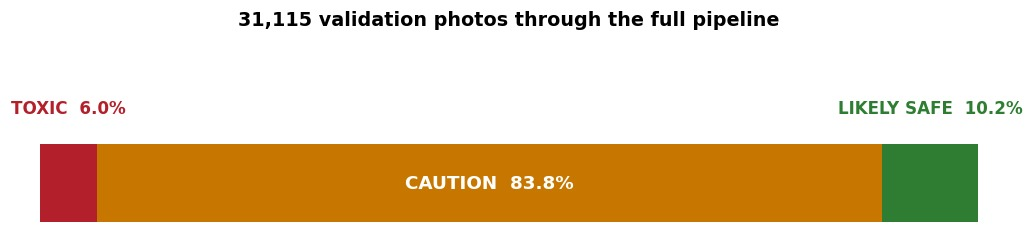

photos that would change tier if every existing non-toxic row were verified: 0


In [7]:
tier_data = json.loads(
    (OUTPUTS_DIR / DEFAULT_RUN / "verdict_tiers_val.json")
    .read_text(encoding="utf-8")
)
counts = tier_data["tiers"]
total = sum(counts.values())

figure, axis = plt.subplots(figsize=(11, 2.4))
left = 0.0
for tier in ("toxic", "caution", "likely_safe"):
    share = counts.get(tier, 0) / total
    axis.barh(0, share, left=left, color=TIER_COLOR[tier], height=0.5)
    if share >= 0.15:
        axis.text(left + share / 2, 0, f"{TIER_LABEL[tier]}  {share:.1%}",
                  ha="center", va="center", color="white", fontsize=12,
                  fontweight="bold")
    else:
        axis.text(left + share / 2, 0.42, f"{TIER_LABEL[tier]}  {share:.1%}",
                  ha="center", va="bottom", color=TIER_COLOR[tier],
                  fontsize=11, fontweight="bold")
    left += share
axis.set_xlim(0, 1)
axis.set_ylim(-0.35, 0.95)
axis.axis("off")
axis.set_title(f"{total:,} validation photos through the full pipeline",
               fontsize=12.5, fontweight="bold")
plt.show()

ceiling = json.loads(
    (OUTPUTS_DIR / DEFAULT_RUN / "verification_ceiling_val.json")
    .read_text(encoding="utf-8")
)
print(f"photos that would change tier if every existing non-toxic row "
      f"were verified: {sum(ceiling['flipped'].values())}")

CAUTION takes 83.8%, and that is a statement about the table rather than
the classifier.

[`01_the_data_problem`](01_the_data_problem.ipynb) measured what
verification would buy by re-running every photograph against a table
where existing non-toxic rows counted as verified. **Nothing moved.**
All 28 PlantNet species with an exact non-toxic row are already
verified, so there is no backlog to clear.

The constraint is absence, not verification. 726 species have no row to
check. Writing rows for species that have none is the most valuable
remaining work in the project, and no amount of model accuracy
substitutes for it.